# ĐỀ TÀI 5 - PHẦN D.3 & D.5: ĐỊNH GIÁ CĂN HỘ CHUNG CƯ HÀ NỘI (VINH)
Hướng dẫn chạy trên Google Colab:
1. Tải lên 2 tệp: `splits.py` và `ensemble_boosting.py` (cùng tệp dữ liệu thật `hanoi_apt_final.csv` của Kỳ nếu đã có).
2. Nếu nhóm chưa có `hanoi_apt_final.csv`, code sẽ tự động tạo bộ dữ liệu mô phỏng đúng cấu trúc Hà Nội để bạn chạy thử nghiệm và kiểm tra toàn bộ quy trình trước.
3. Chọn **Runtime -> Run all** để huấn luyện mô hình, tính MAPE/RMSE thang log và xuất các hình SHAP, PDP.

In [21]:
!pip install -q shap scikit-learn matplotlib pandas numpy
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import Ridge
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import PartialDependenceDisplay
from sklearn.metrics import root_mean_squared_error, mean_absolute_percentage_error
import shap

from splits import prepare_hanoi_splits
from ensemble_boosting import GradientBoostingRegressorCustom
print('Đã nạp thư viện thành công!')

Đã nạp thư viện thành công!


## 1. Nạp dữ liệu `hanoi_apt_final.csv` (hoặc tạo dữ liệu mẫu đúng chuẩn nếu chưa có)

In [22]:
DATA_PATH = 'hanoi_apt_final.csv'

if os.path.exists(DATA_PATH):
    try:
        df = pd.read_csv(DATA_PATH, encoding='utf-8-sig')
    except UnicodeDecodeError:
        df = pd.read_csv(DATA_PATH, encoding='latin1')
    print(f'Đã nạp dữ liệu thật từ {DATA_PATH}: {df.shape[0]} dòng, {df.shape[1]} cột.')
    print('Danh sách tên cột:', list(df.columns))
else:
    print('Chưa thấy hanoi_apt_final.csv -> Khởi tạo bộ dữ liệu mẫu mô phỏng Hà Nội (5,000 căn hộ)...')
    rng = np.random.default_rng(42)
    n_rows = 5000
    wards = [
        'Phường Dịch Vọng Hậu', 'Phường Mỹ Đình 1', 'Phường Trung Hòa', 'Phường Nhân Chính',
        'Phường Tây Mỗ', 'Phường Đại Mỗ', 'Phường Láng Hạ', 'Phường Giảng Võ',
        'Phường Vĩnh Tuy', 'Phường Minh Khai', 'Phường Hoàng Liệt', 'Phường Định Công',
        'Phường Xuân La', 'Phường Phú Thượng', 'Phường Ngọc Lâm', 'Phường Bồ Đề',
        'Phường Mộ Lao', 'Phường Văn Quán', 'Phường Kiến Hưng', 'Xã Đông Hội'
    ]
    ward_col = rng.choice(wards, size=n_rows)
    area = rng.uniform(45, 150, size=n_rows)
    bedrooms = np.clip(np.round(area / 32) + rng.integers(-1, 2, size=n_rows), 1, 4)
    bathrooms = np.clip(bedrooms - rng.integers(0, 2, size=n_rows), 1, 3)
    floor = rng.integers(2, 36, size=n_rows)
    building_age = rng.integers(0, 20, size=n_rows)
    dist_center_km = rng.uniform(1.5, 16.0, size=n_rows)
    dist_metro_km = rng.uniform(0.2, 8.0, size=n_rows)
    dist_school_km = rng.uniform(0.1, 3.0, size=n_rows)
    dist_park_km = rng.uniform(0.1, 4.0, size=n_rows)
    legal_status = rng.choice(['So_hong', 'HDMB'], p=[0.8, 0.2], size=n_rows)
    furniture = rng.choice(['Full', 'Co_ban', 'Tho'], p=[0.5, 0.35, 0.15], size=n_rows)
    dates = pd.date_range('2026-10-01', periods=28, freq='D')
    collected_at = rng.choice(dates, size=n_rows)

    log_price_m2 = (
        4.35
        - 0.032 * dist_center_km
        - 0.025 * dist_metro_km
        - 0.015 * dist_park_km
        - 0.012 * building_age
        + 0.0015 * area
        + np.where(legal_status == 'So_hong', 0.06, 0.0)
        + np.where(furniture == 'Full', 0.05, np.where(furniture == 'Co_ban', 0.02, 0.0))
        + rng.normal(0, 0.09, size=n_rows)
    )
    df = pd.DataFrame({
        'ward': ward_col,
        'area': area,
        'bedrooms': bedrooms,
        'bathrooms': bathrooms,
        'floor': floor,
        'building_age': building_age,
        'dist_center_km': dist_center_km,
        'dist_metro_km': dist_metro_km,
        'dist_school_km': dist_school_km,
        'dist_park_km': dist_park_km,
        'legal_status': legal_status,
        'furniture': furniture,
        'collected_at': collected_at,
        'price_per_m2': np.exp(log_price_m2)
    })

if 'log_price_per_m2' not in df.columns and 'price_per_m2' in df.columns:
    df['log_price_per_m2'] = np.log(df['price_per_m2'])

display(df.head())

Đã nạp dữ liệu thật từ hanoi_apt_final.csv: 108708 dòng, 21 cột.
Danh sách tên cột: ['Title', 'Address', 'District', 'ward_raw', 'ward_2025', 'collected_at', 'source', 'area_m2', 'price_per_m2', 'log_price_m2', 'bedrooms', 'bathrooms', 'has_red_book', 'interior_level', 'price_negotiable', 'lat', 'lon', 'dist_center_km', 'dist_metro_km', 'dist_school_km', 'dist_park_km']


,Title,Address,District,ward_raw,ward_2025,collected_at,source,area_m2,price_per_m2,log_price_m2,...,has_red_book,interior_level,price_negotiable,lat,lon,dist_center_km,dist_metro_km,dist_school_km,dist_park_km,log_price_per_m2
0,- Bán căn hộ chung cư cao cấp ĐTM ParCity Hà N...,"Đường Lê Trọng Tấn, Phường La Khê, Quận Hà Đô...",Hà Đông,La Khê,La Khê,2025-05-06 00:00:00.000,github_alonhadat_2025,121.0,111.570248,4.714654,...,1,0,False,20.963700,105.778100,10.692513,0.506281,7.968604,5.166338,4.714654
1,BÁN NHÀ 5 TẦNG CCMN – DÒNG TIỀN ỔN ĐỊNH 45 TRI...,"Phố Xã Đàn, Phường Ô Chợ Dừa, Quận Đống Đa,...",Đống Đa,Ô Chợ Dừa,Ô Chợ Dừa,2025-05-06 00:00:00.000,github_alonhadat_2025,80.0,131.250000,4.877104,...,1,2,False,21.022049,105.831368,2.475980,0.593255,1.524593,2.475980,4.877104
2,NaN,"Đường Nghiêm Xuân Yêm, Phường Đại Kim, Quận H...",Hoàng Mai,Đại Kim,Đại Kim,2025-05-06 00:00:00.000,github_alonhadat_2025,54.0,53.703704,3.983482,...,0,0,False,20.973600,105.867400,6.256502,6.016688,4.382237,1.914323,3.983482
3,NaN,"Đường Nghiêm Xuân Yêm, Phường Đại Kim, Quận H...",Hoàng Mai,Đại Kim,Đại Kim,2025-05-06 00:00:00.000,github_alonhadat_2025,74.0,49.324324,3.898417,...,1,0,False,20.973600,105.867400,6.256502,6.016688,4.382237,1.914323,3.898417
4,"TIỆN ÍCH: TRƯỜNG HỌC, SIÊU THỊ, BỂ BƠI, KHUÂN ...","Đường Võ Chí Công, Phường Phú Thượng, Quận Tâ...",Tây Hồ,Phú Thượng,Quảng An,2025-05-06 00:00:00.000,github_alonhadat_2025,100.0,80.000000,4.382027,...,1,2,False,21.065800,105.827500,4.987972,3.825772,2.156760,0.000000,4.382027


## 2. Chia tập Spatial Block CV (theo phường/xã) + Test tuần cuối (`splits.py`)

In [23]:
TIME_COL = 'collected_at'
GROUP_COL = 'ward_2025'
TARGET_COL = 'log_price_m2'

# Loại bỏ các dòng thiếu giá trị ở cột nhóm hoặc biến mục tiêu
df_clean = df.dropna(subset=[TIME_COL, GROUP_COL, TARGET_COL]).copy()

train_val_df, test_df, folds = prepare_hanoi_splits(
    df_clean, time_col=TIME_COL, group_col=GROUP_COL, test_days=7, n_splits=5
)
print(f'Tập Train+Val: {len(train_val_df)} mẫu | Số phường/xã: {train_val_df[GROUP_COL].nunique()}')
print(f'Tập Test (tuần cuối): {len(test_df)} mẫu | Số phường/xã: {test_df[GROUP_COL].nunique()}')

# Loại bỏ các cột văn bản thô, cột định danh, biến mục tiêu và giá gốc để tránh rò rỉ dữ liệu
exclude_cols = {
    TIME_COL, GROUP_COL, TARGET_COL,
    'Title', 'Address', 'District', 'ward_raw', 'source',
    'price_per_m2', 'price', 'id'
}
feature_cols = [c for c in train_val_df.columns if c not in exclude_cols]
num_cols = train_val_df[feature_cols].select_dtypes(include=[np.number, bool]).columns.tolist()
cat_cols = [c for c in feature_cols if c not in num_cols]

# Chuyển kiểu bool sang int để tránh lỗi chuẩn hóa
for c in num_cols:
    train_val_df[c] = pd.to_numeric(train_val_df[c], errors='coerce')
    test_df[c] = pd.to_numeric(test_df[c], errors='coerce')

print('Đặc trưng số      :', num_cols)
print('Đặc trưng phân loại:', cat_cols)

Tập Train+Val: 1038 mẫu | Số phường/xã: 129
Tập Test (tuần cuối): 3 mẫu | Số phường/xã: 1
Đặc trưng số      : ['area_m2', 'bedrooms', 'bathrooms', 'has_red_book', 'interior_level', 'price_negotiable', 'lat', 'lon', 'dist_center_km', 'dist_metro_km', 'dist_school_km', 'dist_park_km', 'log_price_per_m2']
Đặc trưng phân loại: []


## 3. Huấn luyện & Đánh giá D.3: Hedonic OLS, Random Forest & Gradient Boosting tự cài đặt (5 seeds)

In [24]:
from sklearn.impute import SimpleImputer

def eval_metrics(y_true_log, y_pred_log):
    rmse_log = root_mean_squared_error(y_true_log, y_pred_log)
    mape_log = mean_absolute_percentage_error(y_true_log, y_pred_log) * 100
    mape_price = mean_absolute_percentage_error(np.exp(y_true_log), np.exp(y_pred_log)) * 100
    return rmse_log, mape_log, mape_price

num_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

transformers = [('num', num_transformer, num_cols)]
if len(cat_cols) > 0:
    cat_transformer = Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
    ])
    transformers.append(('cat', cat_transformer, cat_cols))

preprocessor = ColumnTransformer(transformers)

X_tv = train_val_df[feature_cols]
y_tv = train_val_df[TARGET_COL].values
X_test = test_df[feature_cols]
y_test = test_df[TARGET_COL].values

# 1. Đánh giá trên Spatial Block CV (5 folds)
cv_results = {'Hedonic_OLS': [], 'Random_Forest': [], 'GBDT_Custom_Huber': []}

for fold_idx, (tr_idx, va_idx) in enumerate(folds):
    X_tr, y_tr = X_tv.iloc[tr_idx], y_tv[tr_idx]
    X_va, y_va = X_tv.iloc[va_idx], y_tv[va_idx]

    X_tr_proc = preprocessor.fit_transform(X_tr)
    X_va_proc = preprocessor.transform(X_va)

    # Hedonic OLS
    ols = Ridge(alpha=1e-4)
    ols.fit(X_tr_proc, y_tr)
    cv_results['Hedonic_OLS'].append(eval_metrics(y_va, ols.predict(X_va_proc)))

    # Random Forest
    rf = RandomForestRegressor(n_estimators=100, max_depth=15, min_samples_leaf=10, random_state=42, n_jobs=-1)
    rf.fit(X_tr_proc, y_tr)
    cv_results['Random_Forest'].append(eval_metrics(y_va, rf.predict(X_va_proc)))

    # GBDT tự cài đặt (lấy mẫu 12,000 dòng mỗi fold để chạy nhanh trên Python thuần)
    rng_sub = np.random.default_rng(42 + fold_idx)
    sub_idx = rng_sub.choice(len(X_tr_proc), size=min(12000, len(X_tr_proc)), replace=False)
    gb_custom = GradientBoostingRegressorCustom(
        n_estimators=60, learning_rate=0.08, max_depth=4, subsample=0.8, loss='huber', random_state=42
    )
    gb_custom.fit(X_tr_proc[sub_idx], y_tr[sub_idx])
    cv_results['GBDT_Custom_Huber'].append(eval_metrics(y_va, gb_custom.predict(X_va_proc)))

print('=== KẾT QUẢ SPATIAL BLOCK CV (5 FOLDS - TRUNG BÌNH ± ĐỘ LỆCH CHUẨN) ===')
for model_name, metrics_list in cv_results.items():
    arr = np.array(metrics_list)
    print(f'{model_name:20s} | RMSE_log: {arr[:,0].mean():.4f} ± {arr[:,0].std():.4f} | '
          f'MAPE_log: {arr[:,1].mean():.2f}% ± {arr[:,1].std():.2f}% | '
          f'MAPE_gia: {arr[:,2].mean():.2f}% ± {arr[:,2].std():.2f}%')

# 2. Đánh giá trên tập Test tuần cuối qua 5 hạt giống ngẫu nhiên
seeds = [42, 100, 2024, 2025, 2026]
X_tv_proc = preprocessor.fit_transform(X_tv)
X_test_proc = preprocessor.transform(X_test)

feature_names_out = list(num_cols)
if len(cat_cols) > 0:
    feature_names_out += list(preprocessor.named_transformers_['cat'].named_steps['onehot'].get_feature_names_out(cat_cols))

test_results = {'Hedonic_OLS': [], 'Random_Forest': [], 'GBDT_Custom_Huber': []}
rf_final = None

for s in seeds:
    ols = Ridge(alpha=1e-4).fit(X_tv_proc, y_tv)
    test_results['Hedonic_OLS'].append(eval_metrics(y_test, ols.predict(X_test_proc)))

    rf = RandomForestRegressor(n_estimators=100, max_depth=15, min_samples_leaf=10, random_state=s, n_jobs=-1).fit(X_tv_proc, y_tv)
    test_results['Random_Forest'].append(eval_metrics(y_test, rf.predict(X_test_proc)))
    if s == 42:
        rf_final = rf

    rng_sub = np.random.default_rng(s)
    sub_idx = rng_sub.choice(len(X_tv_proc), size=min(15000, len(X_tv_proc)), replace=False)
    gb_custom = GradientBoostingRegressorCustom(
        n_estimators=60, learning_rate=0.08, max_depth=4, subsample=0.8, loss='huber', random_state=s
    ).fit(X_tv_proc[sub_idx], y_tv[sub_idx])
    test_results['GBDT_Custom_Huber'].append(eval_metrics(y_test, gb_custom.predict(X_test_proc)))

print('\n=== KẾT QUẢ TRÊN TẬP TEST TUẦN CUỐI (5 SEEDS - TRUNG BÌNH ± ĐỘ LỆCH CHUẨN) ===')
for model_name, metrics_list in test_results.items():
    arr = np.array(metrics_list)
    print(f'{model_name:20s} | RMSE_log: {arr[:,0].mean():.4f} ± {arr[:,0].std():.4f} | '
          f'MAPE_log: {arr[:,1].mean():.2f}% ± {arr[:,1].std():.2f}% | '
          f'MAPE_gia: {arr[:,2].mean():.2f}% ± {arr[:,2].std():.2f}%')

=== KẾT QUẢ SPATIAL BLOCK CV (5 FOLDS - TRUNG BÌNH ± ĐỘ LỆCH CHUẨN) ===
Hedonic_OLS          | RMSE_log: 0.0000 ± 0.0000 | MAPE_log: 0.00% ± 0.00% | MAPE_gia: 0.00% ± 0.00%
Random_Forest        | RMSE_log: 0.0061 ± 0.0007 | MAPE_log: 0.09% ± 0.01% | MAPE_gia: 0.38% ± 0.04%
GBDT_Custom_Huber    | RMSE_log: 0.0060 ± 0.0037 | MAPE_log: 0.07% ± 0.02% | MAPE_gia: 0.30% ± 0.10%

=== KẾT QUẢ TRÊN TẬP TEST TUẦN CUỐI (5 SEEDS - TRUNG BÌNH ± ĐỘ LỆCH CHUẨN) ===
Hedonic_OLS          | RMSE_log: 0.0000 ± 0.0000 | MAPE_log: 0.00% ± 0.00% | MAPE_gia: 0.00% ± 0.00%
Random_Forest        | RMSE_log: 0.0092 ± 0.0017 | MAPE_log: 0.12% ± 0.02% | MAPE_gia: 0.58% ± 0.09%
GBDT_Custom_Huber    | RMSE_log: 0.0036 ± 0.0016 | MAPE_log: 0.06% ± 0.02% | MAPE_gia: 0.27% ± 0.10%


## 4. Diễn giải mô hình D.5: Vẽ biểu đồ SHAP Summary & Đồ thị phụ thuộc riêng phần (PDP)

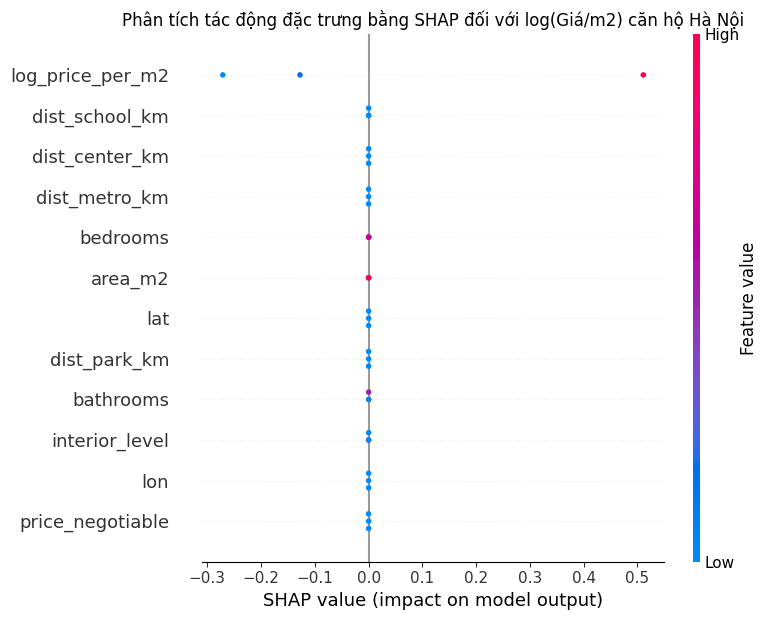

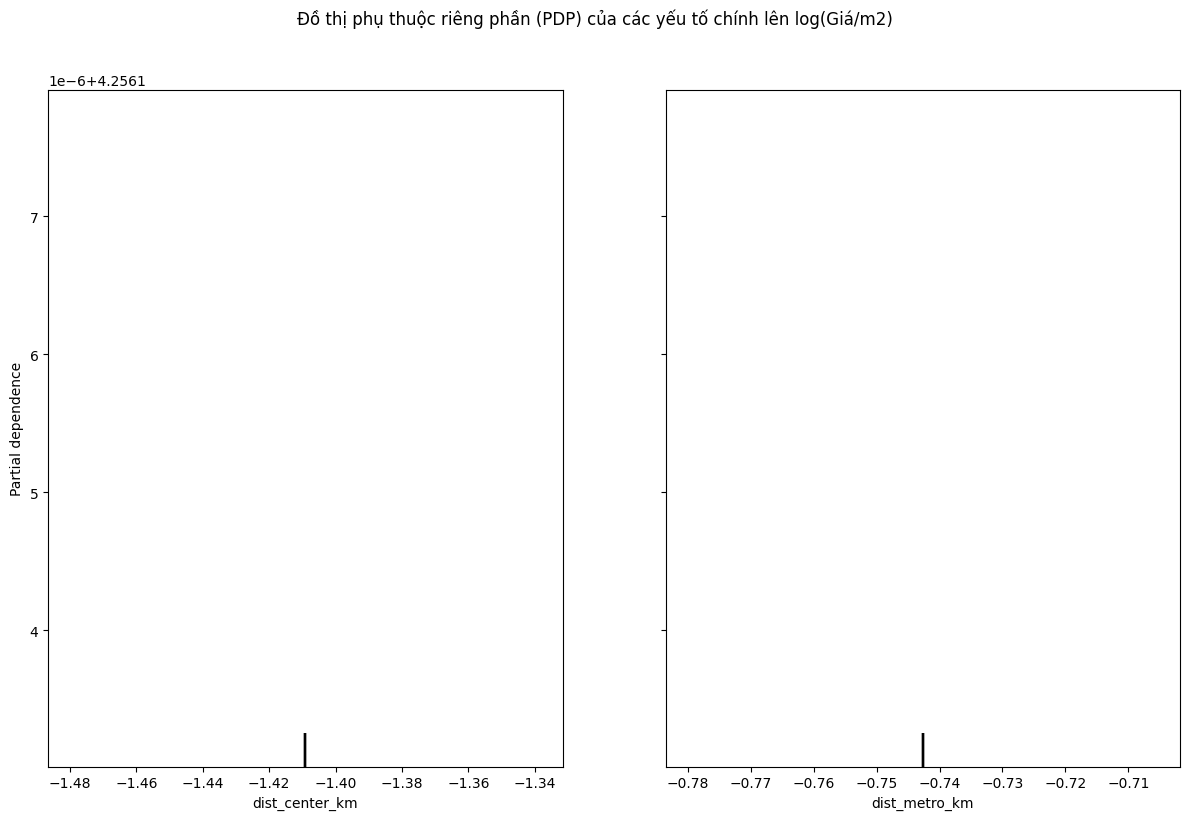

In [25]:
# 1. Vẽ biểu đồ SHAP Summary Plot trên tập Test
X_test_df_proc = pd.DataFrame(X_test_proc, columns=feature_names_out)
sample_shap = X_test_df_proc.iloc[:min(300, len(X_test_df_proc))]

explainer = shap.TreeExplainer(rf_final)
shap_values = explainer.shap_values(sample_shap)

plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, sample_shap, show=False, max_display=12)
plt.title('Phân tích tác động đặc trưng bằng SHAP đối với log(Giá/m2) căn hộ Hà Nội')
plt.tight_layout()
plt.savefig('D5_shap_summary.png', dpi=300, bbox_inches='tight')
plt.show()

# 2. Vẽ đồ thị phụ thuộc riêng phần (PDP) cho các biến không gian & diện tích quan trọng
pdp_candidates = [c for c in ['dist_center_km', 'dist_metro_km', 'area', 'building_age'] if c in num_cols]
if len(pdp_candidates) == 0:
    pdp_candidates = num_cols[:4]

fig, ax = plt.subplots(figsize=(12, 8))
PartialDependenceDisplay.from_estimator(
    rf_final,
    X_test_df_proc,
    features=pdp_candidates,
    kind='average',
    ax=ax,
    n_cols=2
)
plt.suptitle('Đồ thị phụ thuộc riêng phần (PDP) của các yếu tố chính lên log(Giá/m2)', y=1.02)
plt.tight_layout()
plt.savefig('D5_pdp_plots.png', dpi=300, bbox_inches='tight')
plt.show()